# 04 · Visualizaciones y dashboard

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Raíz del proyecto: el notebook se ejecuta desde la carpeta notebooks/
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import metrics as mt
import visualizations as vz

DIR_FIGURAS = RAIZ / "outputs" / "figures"
RUTA_DASHBOARD = RAIZ / "outputs" / "dashboard.html"

# Métricas por reseña (calculadas en el notebook 03)
resenas = pd.read_csv(RAIZ / "data" / "results" / "metricas_por_resena.csv")
resenas["valoracion"] = pd.Categorical(resenas["valoracion"], ["negativa", "intermedia", "positiva"], ordered=True)
resenas["genero_es"] = resenas["genero"].map(vz.GENEROS_ES)

# Tokens sin puntuación, con el género y la valoración de su reseña
tokens = mt.cargar_tokens(RAIZ / "data" / "results" / "pos_analysis.csv")
palabras = mt.sin_puntuacion(tokens).merge(resenas[["id", "genero_es", "valoracion"]], on="id")

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print(f"{len(resenas)} reseñas · {len(palabras):,} tokens sin puntuación")

3000 reseñas · 555,645 tokens sin puntuación


## Figura 1 · Distribución de categorías gramaticales por género

Porcentaje de tokens de cada categoría (UPOS de spaCy) dentro de cada género. Se muestran las 9 categorías más frecuentes.

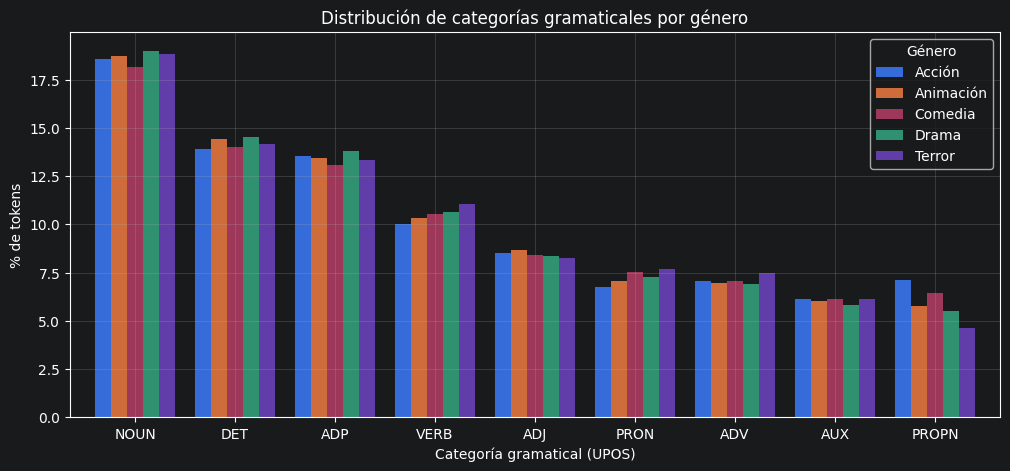

In [2]:
principales = ["NOUN", "DET", "ADP", "VERB", "ADJ", "PRON", "ADV", "AUX", "PROPN"]
distribucion = pd.crosstab(palabras["upos_spacy"], palabras["genero_es"], normalize="columns") * 100

fig, ax = plt.subplots(figsize=(12, 5))
distribucion.loc[principales].plot.bar(ax=ax, rot=0, width=0.8)
ax.set_title("Distribución de categorías gramaticales por género")
ax.set_xlabel("Categoría gramatical (UPOS)")
ax.set_ylabel("% de tokens")
ax.legend(title="Género")
vz.guardar_figura(fig, DIR_FIGURAS, "01_pos_por_genero")

**Qué muestra:** los cinco géneros tienen distribuciones muy parecidas: la estructura gramatical de una reseña depende poco del género de la película. La diferencia más visible está en los **nombres propios (PROPN)**: son más frecuentes en las reseñas de Acción (7 %) que en las de Terror (4,6 %). Las reseñas de Acción mencionan más actores, directores y franquicias.

## Figura 2 · Métricas por género (preguntas A1 y A2)

Promedio por reseña de cuatro métricas. Arriba, las de las preguntas A1 (adjetivos) y A2 (verbos).

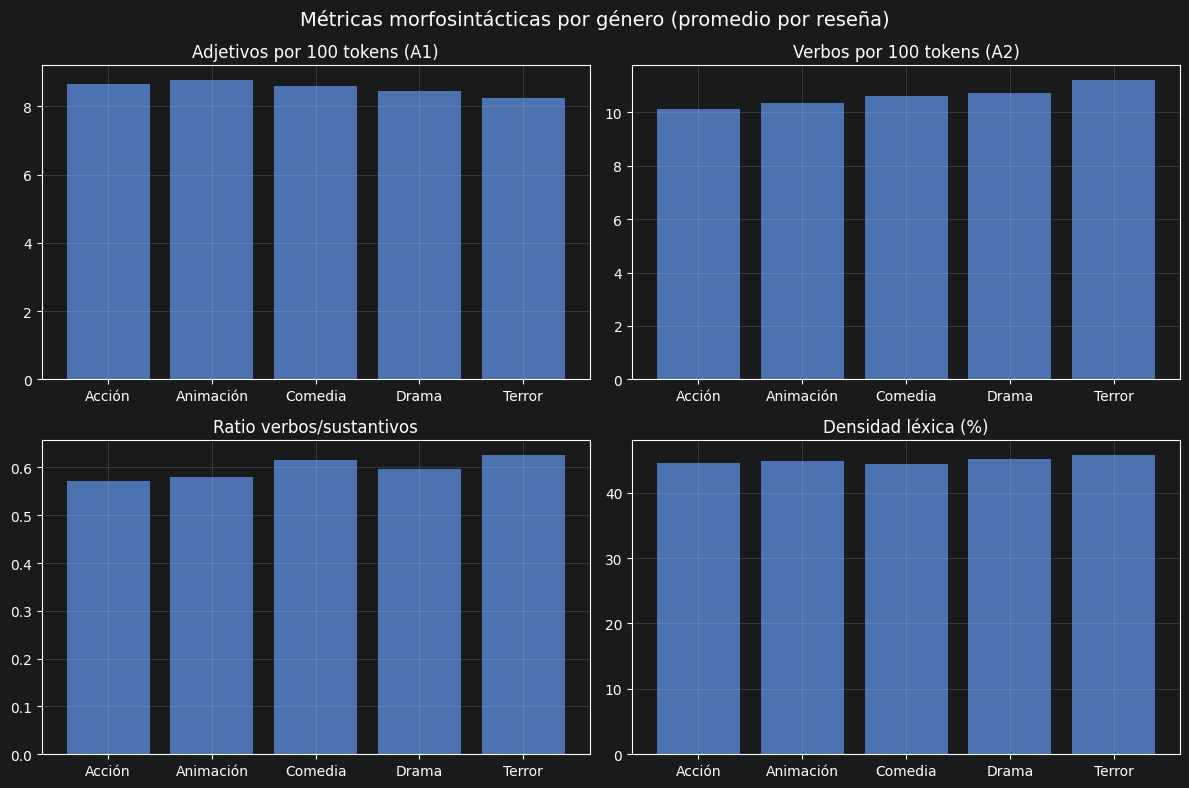

In [3]:
graficos = [("idx_adjetivos", "Adjetivos por 100 tokens (A1)"),
            ("idx_verbos", "Verbos por 100 tokens (A2)"),
            ("ratio_verbos_sustantivos", "Ratio verbos/sustantivos"),
            ("densidad_lexica", "Densidad léxica (%)")]

fig, ejes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (metrica, titulo) in zip(ejes.flat, graficos):
    promedios = resenas.groupby("genero_es")[metrica].mean()
    ax.bar(promedios.index, promedios.values, color="#4C72B0")
    ax.set_title(titulo)
fig.suptitle("Métricas morfosintácticas por género (promedio por reseña)", fontsize=14)
fig.tight_layout()
vz.guardar_figura(fig, DIR_FIGURAS, "02_metricas_por_genero")

**Qué muestra:** las diferencias entre géneros son pequeñas: todas las barras tienen alturas parecidas.
- **A1:** Terror tiene el índice de adjetivos *más bajo*, no más alto que Comedia.
- **A2:** Acción tiene *menos* verbos que Drama, y Terror es el género con más.

Ambas hipótesis se descartan (ver notebook 03).

## Figura 3 · Adjetivos y negaciones a lo largo de la calificación (pregunta B1)

Promedio por reseña para cada calificación de 1 a 10.

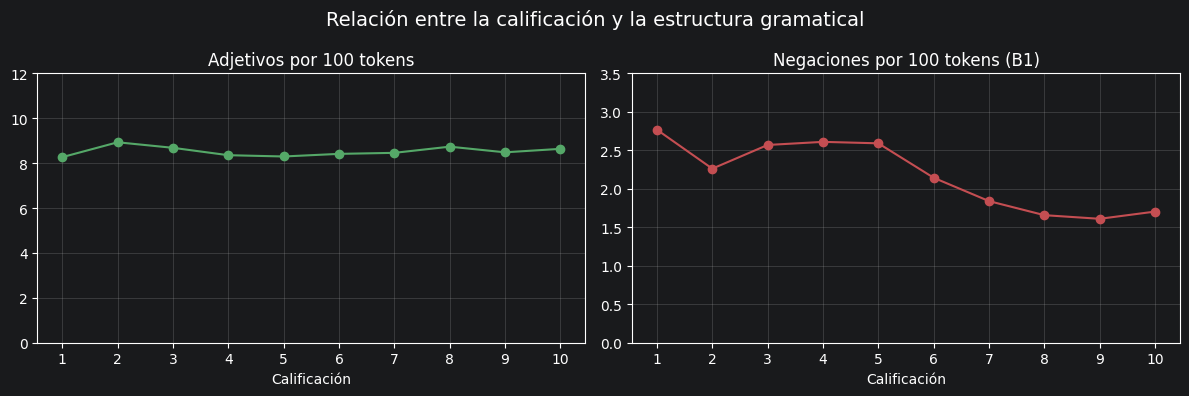

In [4]:
por_calificacion = resenas.groupby("calificacion")[["idx_adjetivos", "idx_negacion"]].mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(por_calificacion.index, por_calificacion["idx_adjetivos"], marker="o", color="#55A868")
ax1.set_title("Adjetivos por 100 tokens")
ax1.set_ylim(0, 12)
ax2.plot(por_calificacion.index, por_calificacion["idx_negacion"], marker="o", color="#C44E52")
ax2.set_title("Negaciones por 100 tokens (B1)")
ax2.set_ylim(0, 3.5)
for ax in (ax1, ax2):
    ax.set_xlabel("Calificación")
    ax.set_xticks(range(1, 11))
fig.suptitle("Relación entre la calificación y la estructura gramatical", fontsize=14)
fig.tight_layout()
vz.guardar_figura(fig, DIR_FIGURAS, "03_calificacion_adjetivos_negaciones")

**Qué muestra:**
- **Negaciones (B1):** bajan claramente al subir la calificación. Las reseñas de 1–5 usan bastantes más negaciones que las de 7–10. Es el patrón más claro del análisis.
- **Adjetivos:** se mantienen planos en toda la escala. Las reseñas extremas (1–2 o 9–10) no usan más adjetivos que las intermedias.

## Figura 4 · Longitud por valoración (pregunta B6)

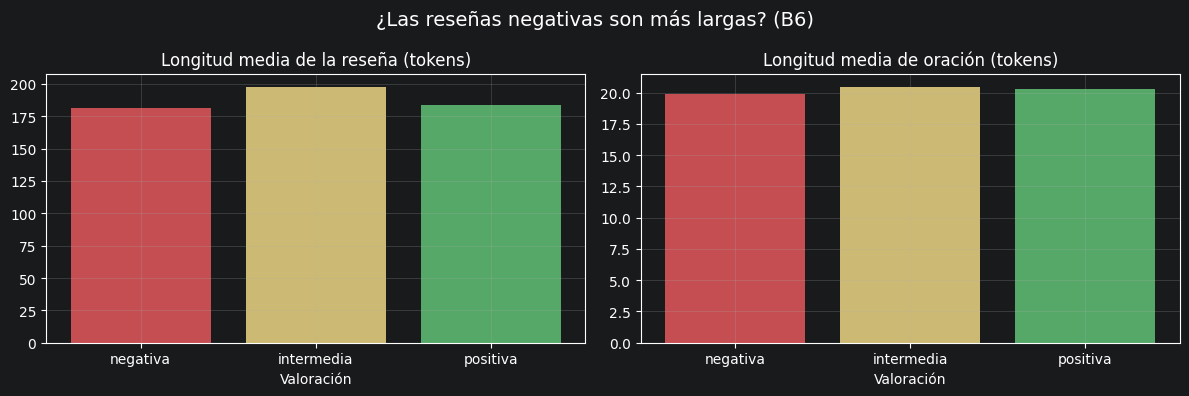

In [5]:
por_valoracion = resenas.groupby("valoracion", observed=True)[["n_tokens", "long_oracion"]].mean()
colores = ["#C44E52", "#CCB974", "#55A868"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.bar(por_valoracion.index, por_valoracion["n_tokens"], color=colores)
ax1.set_title("Longitud media de la reseña (tokens)")
ax2.bar(por_valoracion.index, por_valoracion["long_oracion"], color=colores)
ax2.set_title("Longitud media de oración (tokens)")
for ax in (ax1, ax2):
    ax.set_xlabel("Valoración")
fig.suptitle("¿Las reseñas negativas son más largas? (B6)", fontsize=14)
fig.tight_layout()
vz.guardar_figura(fig, DIR_FIGURAS, "04_longitud_por_valoracion")

**Qué muestra:** las reseñas negativas y positivas tienen prácticamente la misma longitud, tanto de reseña como de oración. Las intermedias son algo más largas. La respuesta a B6 es **no**.

## Figura 5 · Evolución por año (preguntas C2 y C4)

Promedio por año de la reseña. Se excluyen 1998 y 2018, que tienen muy pocas reseñas (24 y 3) y darían promedios poco fiables. La línea punteada separa los dos periodos.

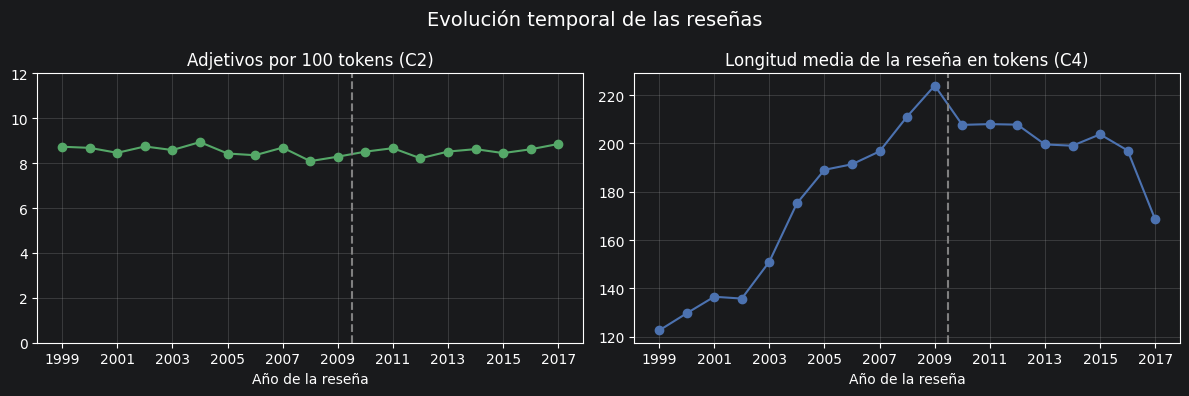

In [6]:
por_anio = resenas[resenas["anio"].between(1999, 2017)].groupby("anio")[["idx_adjetivos", "n_tokens"]].mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(por_anio.index, por_anio["idx_adjetivos"], marker="o", color="#55A868")
ax1.set_title("Adjetivos por 100 tokens (C2)")
ax1.set_ylim(0, 12)  # eje desde 0: muestra que la proporción casi no cambia
ax2.plot(por_anio.index, por_anio["n_tokens"], marker="o", color="#4C72B0")
ax2.set_title("Longitud media de la reseña en tokens (C4)")
for ax in (ax1, ax2):
    ax.axvline(2009.5, linestyle="--", color="gray")  # separación entre periodos
    ax.set_xticks(range(1999, 2018, 2))
    ax.set_xlabel("Año de la reseña")
fig.suptitle("Evolución temporal de las reseñas", fontsize=14)
fig.tight_layout()
vz.guardar_figura(fig, DIR_FIGURAS, "05_evolucion_por_anio")

**Qué muestra:**
- **C2:** la proporción de adjetivos oscila alrededor de 8,5 sin tendencia. **No** cambió con el tiempo.
- **C4:** la longitud de las reseñas **sí** cambió. Crece de forma marcada entre 1999 y 2009, se estabiliza cerca de 200 tokens en 2010–2016 y baja en 2017.

## Figura 6 · Matriz de confusión NLTK vs spaCy

Cada fila es una categoría según spaCy, y muestra cómo etiquetó NLTK esos mismos tokens (en % de la fila). La diagonal es la concordancia. Se omiten las categorías muy poco frecuentes (INTJ, PART, X).

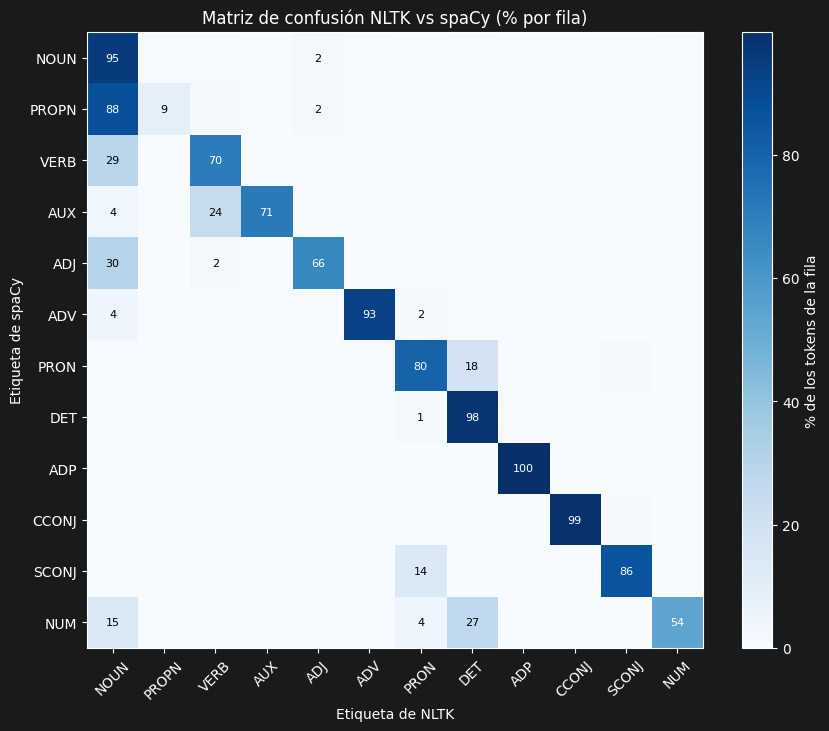

In [7]:
orden = ["NOUN", "PROPN", "VERB", "AUX", "ADJ", "ADV", "PRON", "DET", "ADP", "CCONJ", "SCONJ", "NUM"]
matriz = mt.matriz_confusion(tokens).reindex(index=orden, columns=orden, fill_value=0)

fig, ax = plt.subplots(figsize=(10, 8))
imagen = ax.imshow(matriz, cmap="Blues")
ax.set_xticks(range(len(orden)), orden, rotation=45)
ax.set_yticks(range(len(orden)), orden)
for i in range(len(orden)):          # escribir el % en cada celda
    for j in range(len(orden)):
        valor = matriz.iloc[i, j]
        if valor >= 1:
            ax.text(j, i, f"{valor:.0f}", ha="center", va="center",
                    color="white" if valor > 50 else "black", fontsize=8)
ax.set_xlabel("Etiqueta de NLTK")
ax.set_ylabel("Etiqueta de spaCy")
ax.set_title("Matriz de confusión NLTK vs spaCy (% por fila)")
ax.grid(False)
fig.colorbar(imagen, ax=ax, label="% de los tokens de la fila")
vz.guardar_figura(fig, DIR_FIGURAS, "06_matriz_confusion")

**Qué muestra:**
- La diagonal es oscura en las categorías funcionales (ADP, CCONJ, DET), donde ambas herramientas coinciden casi siempre.
- La **columna NOUN** concentra los errores de NLTK. Allí van casi todos los nombres propios (PROPN) y cerca de un 30 % de los verbos y adjetivos de spaCy: son palabras que NLTK no conoce y etiqueta como sustantivo por defecto.
- **AUX → VERB** refleja la diferencia de criterio con *estar* y *poder*.

## Figura 7 · Adjetivos más característicos por valoración

Para cada adjetivo (lema) se compara su frecuencia en las reseñas positivas y en las negativas (por cada 100 adjetivos). Se muestran los 10 que más usa cada grupo en comparación con el otro (función `vz.adjetivos_caracteristicos`).

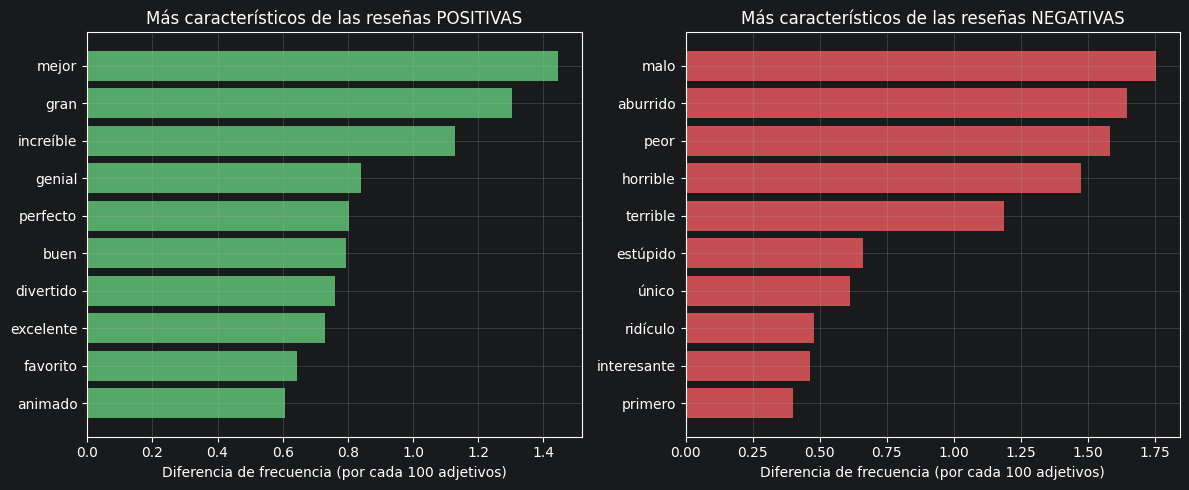

In [8]:
adjetivos = palabras[palabras["upos_spacy"] == "ADJ"]
positivos = vz.adjetivos_caracteristicos(adjetivos, "positiva", "negativa").sort_values()
negativos = vz.adjetivos_caracteristicos(adjetivos, "negativa", "positiva").sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.barh(positivos.index, positivos.values, color="#55A868")
ax1.set_title("Más característicos de las reseñas POSITIVAS")
ax2.barh(negativos.index, negativos.values, color="#C44E52")
ax2.set_title("Más característicos de las reseñas NEGATIVAS")
for ax in (ax1, ax2):
    ax.set_xlabel("Diferencia de frecuencia (por cada 100 adjetivos)")
fig.tight_layout()
vz.guardar_figura(fig, DIR_FIGURAS, "07_adjetivos_por_valoracion")

**Qué muestra:** los adjetivos reflejan con claridad la valoración. Las reseñas positivas usan *mejor, gran, increíble, genial, perfecto*; las negativas, *malo, aburrido, peor, horrible, terrible, estúpido*. A diferencia de la *cantidad* de adjetivos, que casi no cambia con la valoración (figura 3), *cuáles* adjetivos se usan sí la distingue.

*Ojo:* *animado* aparece entre los positivos porque la mayoría de las reseñas de Animación son positivas. Refleja la composición de la muestra, no una forma de elogiar.